In [37]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


In [38]:
# -----------------------------
# Load dataset
# -----------------------------
file_path = "C:/Users/hp/Downloads/iris.csv"

data = pd.read_csv(file_path)

print("Original Dataset")
print(data.head())

Original Dataset
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [39]:
print(data.describe())

       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000


In [40]:
# -----------------------------
# Separate Features and Target
# -----------------------------
X = data.drop(columns=["species"])
y = data["species"]

In [41]:
# -----------------------------
# Feature Scaling
# -----------------------------
scaler = StandardScaler()

X_Scaled = scaler.fit_transform(X)
print("\nScaled Features (First 5 rows)")
print(X_Scaled[:5])



Scaled Features (First 5 rows)
[[-0.90068117  1.03205722 -1.3412724  -1.31297673]
 [-1.14301691 -0.1249576  -1.3412724  -1.31297673]
 [-1.38535265  0.33784833 -1.39813811 -1.31297673]
 [-1.50652052  0.10644536 -1.2844067  -1.31297673]
 [-1.02184904  1.26346019 -1.3412724  -1.31297673]]


In [42]:
# --------------------------------------------------
# 5. Apply PCA
# --------------------------------------------------

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_Scaled)

# --------------------------------------------------
# 6. Display transformed data
# --------------------------------------------------

print("\nOriginal dimensions:", X_Scaled.shape)
print("Dimensions after PCA:", X_pca.shape)

print("\nFirst five transformed samples:")
print(X_pca[:5])




Original dimensions: (150, 4)
Dimensions after PCA: (150, 2)

First five transformed samples:
[[-2.26454173  0.5057039 ]
 [-2.0864255  -0.65540473]
 [-2.36795045 -0.31847731]
 [-2.30419716 -0.57536771]
 [-2.38877749  0.6747674 ]]


In [43]:
# --------------------------------------------------
# 7. Explained variance
# Explained variance indicates how much of the total variation (information) present in the original dataset is captured by a principal component.
# --------------------------------------------------

print("\nExplained Variance Ratio:")

for i, variance in enumerate(pca.explained_variance_ratio_):
    print("PC", i+1, ":", round(variance, 4))

total_variance = sum(pca.explained_variance_ratio_)

print("\nTotal variance retained:",
      round(total_variance * 100, 2), "%")




Explained Variance Ratio:
PC 1 : 0.7277
PC 2 : 0.2303

Total variance retained: 95.8 %


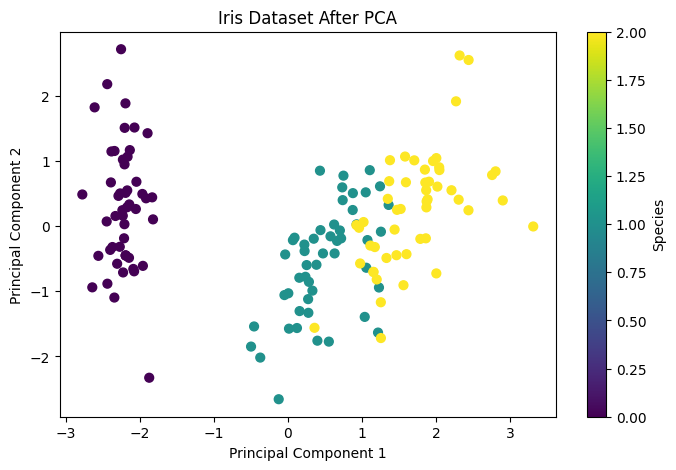

In [44]:
# --------------------------------------------------
# 8. Visualize data after PCA
# --------------------------------------------------

plt.figure(figsize=(8, 5))

if y is not None:
    labels = pd.factorize(y)[0]

    scatter = plt.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="viridis",
        s=40
    )

    plt.colorbar(scatter, label="Species")

else:
    plt.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        s=40
    )

plt.title("Iris Dataset After PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()



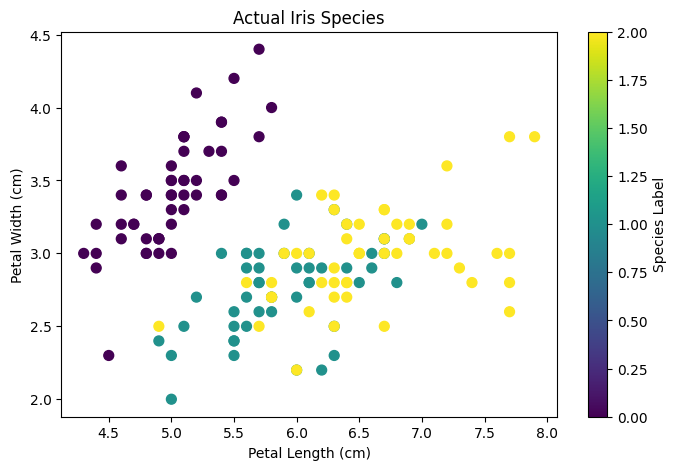

In [45]:
# --------------------------------------------------
# 9. Visualize actual Iris species (optional)
# --------------------------------------------------
# Actual species labels (used only for comparison)
if "Species" in data.columns:
    y_true = data["Species"]

elif "species" in data.columns:
    y_true = data["species"]

else:
    y_true = None


if y_true is not None:

    plt.figure(figsize=(8, 5))

    plt.scatter(
        X.iloc[:, 0],
        X.iloc[:, 1],
        c=pd.factorize(y_true)[0],
        cmap="viridis",
        s=50
    )

    plt.title("Actual Iris Species")
    plt.xlabel("Petal Length (cm)")
    plt.ylabel("Petal Width (cm)")

    plt.colorbar(label="Species Label")

    plt.show()
